<a href="https://colab.research.google.com/github/ntienvo/ML-lab/blob/main/Lab04_KNN_KMeans_Student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 04 — Student Worksheet: KNN and K-Means

**Objective:** Implement K-Nearest Neighbors (KNN) and K-Means from scratch, then compare them with scikit-learn.

Use the provided cells and fill in every `TODO`. Run cells in order. Do not use `species` as an input feature for K-Means.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans

In [ ]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# If Seaborn cannot load the dataset, place penguins.csv in the working directory and load it locally.
penguins = sns.load_dataset("penguins")
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


## Prepare the dataset

Use `bill_length_mm` and `flipper_length_mm` as numerical features and `species` as the classification target. Remove rows with missing values in these columns. Create `X`, `y`, and `X_scaled`.

In [ ]:
features = ["bill_length_mm", "flipper_length_mm"]
target = "species"

# TODO: create `data` by selecting features + target and dropping rows with missing values
data = penguins[features + [target]].dropna()

# TODO: create NumPy arrays X (float) and y
X = data[features].to_numpy(dtype = float)
y = data[target].to_numpy()

# Standardized features are used by the from-scratch K-Means section.
X_scaled = StandardScaler().fit_transform(X)

print("Data shape:", X.shape)
print("\nMissing values after dropping incomple rows:")
print(data.isnull().sum())

print("\nSpecies counts:")
print(data[target].value_counts())

Data shape: (342, 2)

Missing values after dropping incomple rows:
bill_length_mm       0
flipper_length_mm    0
species              0
dtype: int64

Species counts:
species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64


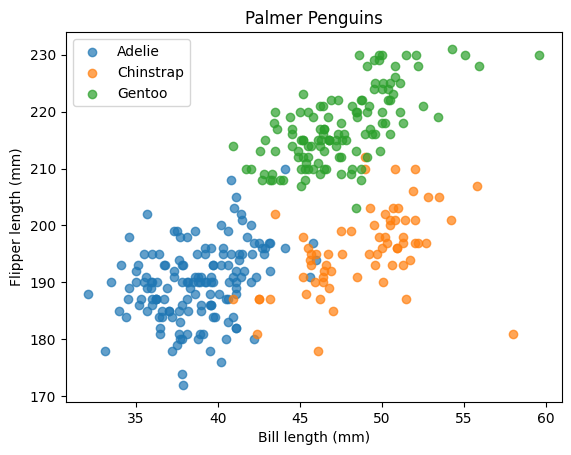

In [ ]:
# TODO: Plot bill_length_mm against flipper_length_mm.
# Use a different color for each species and include axis labels, legend, and title.
plot_data = penguins.dropna(subset=features + [target])
for name, subset in plot_data.groupby("species"):
    plt.scatter(subset["bill_length_mm"], subset["flipper_length_mm"], label=name, alpha=.7)
plt.xlabel("Bill length (mm)");
plt.ylabel("Flipper length (mm)")
plt.legend();
plt.title("Palmer Penguins");
plt.show()

## Part A — KNN from Scratch with OOP

Implement a `KNNClassifier` class.

Requirements:
1. `__init__(k=3)` validates that `k` is a positive integer and stores it.
2. `fit(X, y)` stores the training features and labels and returns `self`.
3. `euclidean_distance(x1, x2)` returns the Euclidean distance.
4. `predict_one(x)` finds the `k` nearest training samples and returns the majority label.
5. `predict(X)` predicts labels for multiple samples.

**Hint:** Use `np.argsort` to find the indices of the smallest distances and `np.unique(..., return_counts=True)` to count labels.

In [ ]:
class KNNClassifier:
    def __init__(self, k=3):
        if not isinstance(k, int) or k <= 0:
          raise ValueError("k phai lon hon 0 va la so nguyen")
        self.k = k
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype = float)
        self.y_train = np.asarray(y)

        if X.ndim != 2 or len(X) != len(y) or len(X) < self.k:
          raise ValueError("Du lieu train khong hop le")
        self.X_train = X.copy()
        self.y_train = y.copy()
        return self

    def euclidean_distance(self, x1, x2):
        x1 = np.asarray(x1, dtype = float)
        x2 = np.asarray(x2, dtype = float)
        return float(np.sqrt(np.sum((x1 - x2)** 2)))

    def predict_one(self, x):
        distances = np.array([self.euclidean_distance(x, train_point) for train_point in self.X_train])

        nearest_indices = np.argsort(distances)[:self.k]
        nearest_labels = self.y_train[nearest_indices]

        labels, counts = np.unique(nearest_labels, return_counts=True)
        tied_labels = labels[counts == counts.max()]

        if len(tied_labels) == 1:
          return tied_labels[0]

        return next(label for label in nearest_labels if label in tied_labels)

    def predict(self, X):
        X = np.atleast_2d(np.array(X, dtype = float))
        return np.array([self.predict_one(row) for row in X])

### Test KNN on a toy dataset

Run your implementation for `k=1` and `k=3`. Do the predictions make sense based on the locations of the points?

In [ ]:
X_toy = np.array([[0, 0], [0, 1], [1, 0], [5, 5], [5, 6], [6, 5]], dtype=float)
y_toy = np.array(["A", "A", "A", "B", "B", "B"])
x_new = np.array([1.2, 1.0])

# TODO: fit a KNN model for k=1 and k=3 and print each prediction
for k in [1,3]:
  model = KNNClassifier(k=k)
  model.fit(X_toy, y_toy)
  print(f"k={k}, prediction={model.predict(x_new)[0]}")

k=1, prediction=A
k=3, prediction=A


### Test the scratch KNN on Palmer Penguins

Split the data into training and test sets, keeping the class proportions similar with `stratify=y`. Fit your classifier and report test accuracy.

In [ ]:
X_train_demo, X_test_demo, y_train_demo, y_test_demo = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# TODO: fit KNNClassifier (try k=5), predict the test set, and print accuracy
knn_model = KNNClassifier(k = 5).fit(X_train_demo, y_train_demo)
y_pred = knn_model.predict(X_test_demo)
print("Sratch KNN test accuracy:", accuracy_score(y_test_demo, y_pred))

Sratch KNN test accuracy: 0.9855072463768116


## Part B — Train/Validation/Test Split and Selecting `k`

Create three separate sets:
- 60% training
- 20% validation
- 20% test

Compare the training and validation accuracy for `k` in `[1, 3, 5, 7, 9, 11, 15, 21]`. Choose the `k` with the best validation accuracy. Use the test set only for the final evaluation.

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=.40, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=.50, random_state=42, stratify=y_temp
)

k_values = [1, 3, 5, 7, 9, 11, 15, 21]
rows = []

# TODO: for each k, fit KNeighborsClassifier on the training set
# TODO: record k, training accuracy, and validation accuracy in rows
# TODO: create a DataFrame named results and display it
# TODO: determine best_k from validation accuracy and print it
for k in k_values:
  model = KNeighborsClassifier(n_neighbors=k)
  model.fit(X_train, y_train)

  rows.append({
      "k": k,
      "train_accuracy": model.score(X_train, y_train),
      "validation_accuracy": model.score(X_val, y_val)
  })

  results = pd.DataFrame(rows)
  display(results)

  best_k = int(results.loc[results["validation_accuracy"].idxmax(), "k"])
  print("Best k from validation: ", best_k)


,k,train_accuracy,validation_accuracy
0,1,1.0,0.926471


Best k from validation:  1


,k,train_accuracy,validation_accuracy
0,1,1.000000,0.926471
1,3,0.956098,0.955882


Best k from validation:  3


,k,train_accuracy,validation_accuracy
0,1,1.000000,0.926471
1,3,0.956098,0.955882
2,5,0.956098,0.955882


Best k from validation:  3


... (6 outputs left out)

,k,train_accuracy,validation_accuracy
0,1,1.000000,0.926471
1,3,0.956098,0.955882
2,5,0.956098,0.955882
3,7,0.956098,0.955882
4,9,0.936585,0.941176
5,11,0.931707,0.941176
6,15,0.931707,0.926471


Best k from validation:  3


,k,train_accuracy,validation_accuracy
0,1,1.000000,0.926471
1,3,0.956098,0.955882
2,5,0.956098,0.955882
3,7,0.956098,0.955882
4,9,0.936585,0.941176
5,11,0.931707,0.941176
6,15,0.931707,0.926471
7,21,0.926829,0.911765


Best k from validation:  3


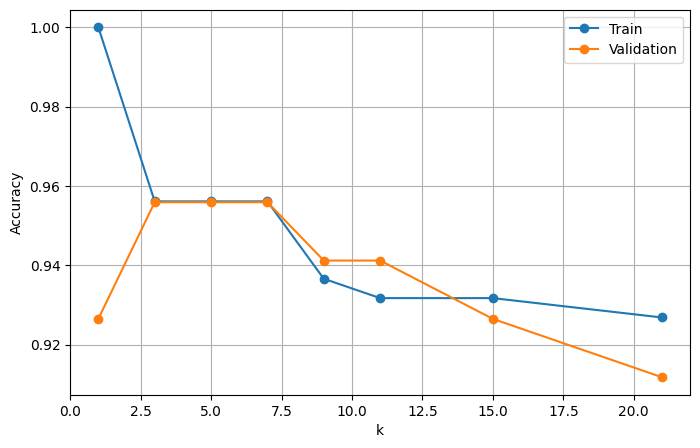

In [ ]:
# TODO: Plot training accuracy and validation accuracy against k.
# Include axis labels, legend, grid, and show the plot.
plt.figure(figsize=(8, 5))
plt.plot(results["k"], results["train_accuracy"], marker="o", label = "Train")
plt.plot(results["k"], results["validation_accuracy"], marker="o", label = "Validation")

plt.xlabel("k")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


In [ ]:
# TODO: Fit a final KNeighborsClassifier using best_k and the training data.
# Evaluate on X_test and print test accuracy and classification_report.
final_model = KNeighborsClassifier(n_neighbors=best_k)
final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)

print("Test accuracy:",accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Test accuracy: 0.9710144927536232
              precision    recall  f1-score   support

      Adelie       0.97      0.97      0.97        31
   Chinstrap       0.92      0.92      0.92        13
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.97        69
   macro avg       0.96      0.96      0.96        69
weighted avg       0.97      0.97      0.97        69



## Part C — Comparing Feature Scaling

KNN is distance-based. Compare validation accuracy:
1. KNN using the original features.
2. A pipeline that standardizes features and then applies KNN.

Use the `best_k` chosen in Part B. Fit each model using only the training set.

In [ ]:
# TODO: Fit an unscaled KNeighborsClassifier and calculate validation accuracy.
# plain_acc = ...

# TODO: Build a Pipeline with StandardScaler and KNeighborsClassifier.
# Fit it on the training set and calculate validation accuracy.
# scaled_acc = ...

# print({"validation_accuracy_without_scaling": plain_acc,
#        "validation_accuracy_with_scaling": scaled_acc})


## Part D — K-Means from Scratch with OOP

Use `X_scaled` (the two standardized numerical features). Do **not** pass species labels to the clustering algorithm.

Implement a `KMeansClustering` class with:
- `initialize_centroids(X, rng)`: choose `k` distinct observations as initial centroids.
- `assign_clusters(X)`: assign each observation to its nearest centroid.
- `update_centroids(X, labels)`: calculate the mean of points assigned to each cluster. If a cluster is empty, keep its previous centroid.
- `fit(X)`: repeat assignment and centroid updates until convergence or `max_iter` is reached. Store final `labels` and `centroids`.

Use Euclidean distance and a tolerance (`tol`) to check centroid movement.

In [ ]:
# Inspect the numerical input used by K-Means.
print("Standardized feature matrix shape:", X_scaled.shape)
print("Feature means (approximately zero):", X_scaled.mean(axis=0).round(3))
print("Feature standard deviations (approximately one):", X_scaled.std(axis=0).round(3))


In [ ]:
class KMeansClustering:
    def __init__(self, k=3, max_iter=100, tol=1e-4, random_state=42):
        # TODO: validate parameters and initialize attributes
        # Store k, max_iter, tol, random_state
        # Initialize centroids and labels to None
        pass

    def initialize_centroids(self, X, rng):
        # TODO: choose k distinct rows from X and return a copy
        pass

    def assign_clusters(self, X):
        # TODO: calculate distances from every sample to every centroid
        # Return the index of the nearest centroid for each sample
        pass

    def update_centroids(self, X, labels):
        # TODO: compute each cluster's mean
        # If a cluster is empty, retain its previous centroid
        pass

    def fit(self, X):
        # TODO: validate X and k
        # TODO: initialize a random generator and initial centroids
        # TODO: repeat assignment/update until movement < tol or max_iter reached
        # TODO: store final labels and centroids; return self
        pass


In [ ]:
# TODO: Fit your KMeansClustering implementation with k=3 on X_scaled.
# Plot the observations colored by cluster and show centroids with a distinct marker.
# Print the number of observations in each cluster.


## Part E — K-Means with scikit-learn and the Elbow Method

Fit scikit-learn's K-Means using the same standardized numerical features. Plot the clusters and centroids. Then calculate inertia for `k=1` through `k=8` and plot the elbow curve.

Finally, compare cluster assignments with species using a cross-tabulation. Species is for interpretation only; it must not be used when fitting K-Means.

In [ ]:
# TODO: Fit sklearn KMeans with n_clusters=3, random_state=42, n_init=10.
# Plot X_scaled colored by cluster and plot the cluster centers.


In [ ]:
# TODO: For k from 1 to 8, fit KMeans and save each model's inertia.
# Plot k against inertia to inspect the elbow curve.


In [ ]:
# TODO: Use pd.crosstab to compare cluster_labels with y (species).


## Reflection Questions

Answer briefly in a Markdown cell below:
1. Why can KNN with `k=1` have high training accuracy but perform poorly on unseen data?
2. How did feature scaling affect KNN validation accuracy? Why might this happen?
3. What are the assignment and centroid-update steps in K-Means?
4. What does inertia measure, and why does it decrease as `k` increases?
5. Why should cluster IDs not be interpreted directly as species labels?
